# Ocular dominance and pRF analyses with three versions of sub-05

sub-05's eye labels are uncertain (`sub05_eye_label_investigation_v2.ipynb`): its designs are certain, but 4 of 5 independent amblyopic-eye signatures and the original readme point to a swap of its two blocks, while `participant-mapping.md` supports the current labels. Every analysis is therefore run three times:

| version | sub-05 |
|---|---|
| **without sub-05** | excluded (10 amblyopes) |
| **sub-05 as labelled** | current labels (runs 5-8 = right eye) |
| **sub-05 swapped** | left and right exchanged for all its data (runs 5-8 = left eye) |

The controls are the same in the three versions.

**OD analysis** (as `od_group_figure_v12.ipynb`):
- % of vertices preferring FE-LE;
- weighted median of the vertex OD index;
- reproducibility of the OD maps between halves of the runs (median r of the 3 splits; crossed-label control);
- amblyopes vs controls.

**pRF analysis** (as `retinotopy_amblyopia.ipynb`):
- pRF R²;
- effective size σ/√n at 2°;
- pCM at 2°;
- CSS exponent n;
- between the eyes: shift of the pRF centres (deg and relative to the size) and correlation of the eccentricity maps.

Comparisons: AE vs FE (paired Wilcoxon), AE vs CTRL and FE vs CTRL (Mann-Whitney), amblyopes vs controls for the between-eye measures. FDR over the 8 ROIs.

Same vertex selection everywhere: the prf_analysis filters on both eyes; weight = mean pRF R² of the two eyes. Data: new fits (`prfmodel`). Read only. Caches: `prf_od_filter_cache/` (shared with retinotopy_amblyopia) and `od_glm_common_cache/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, sys
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

sys.path.insert(0, "{}/../utils".format(os.getcwd()))
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
vcache_dir = '{}/prf_od_filter_cache'.format(fig_dir)
glm_cache_dir = '{}/od_glm_common_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
analysis_info = load_settings([os.path.join(base_dir, project_dir, f) for f in
                               ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])[0]
patients, controls = analysis_info['group-patient'], analysis_info['group-control']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_pcm = analysis_info['maps_names_pcm']
maps_names_css_od = analysis_info['maps_names_css_od']
roi_colors = analysis_info['roi_colors']

task = 'BarsBarsRingsWedges'
rois_method = 'rois-group-mmp'
rois = list(analysis_info[rois_method].keys())
rois_to_plot = 'roi_mmp'
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
fspec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'

ecc_th, size_th, n_th, rsqr_th = analysis_info['ecc_th'], analysis_info['size_th'], analysis_info['n_th'], analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']['psc']
stats_th = analysis_info['stats_th']
stats_col = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'
ecc_fit_range, ref_ecc, min_vertices = [0.5, 6], 2, 20

participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e)[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)}
set_pycortex_config_file('{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir))

target = 'sub-05'
versions = ['without sub-05', 'sub-05 as labelled', 'sub-05 swapped']

## Vertex data (same cache as retinotopy_amblyopia.ipynb)

In [2]:
def source_files(subject):
    fns = {'od': [fspec.format(pp_dir, subject, subject, task, h, 'prf-css_od') for h in 'LR']}
    for e, eye in eyes.items():
        fns['deriv_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_deriv') for h in 'LR']
        fns['stats_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_stats') for h in 'LR']
        fns['pcm_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, '{}_prf-css_pcm'.format(rois_method)) for h in 'LR']
    return fns


def load_subject(subject):
    fns = source_files(subject)
    all_fns = [f for v in fns.values() for f in v]
    if not all(os.path.isfile(f) for f in all_fns):
        return None
    cache_fn = '{}/{}_prf-od-filter-cache.tsv.gz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(f) for f in all_fns)
    if os.path.isfile(cache_fn) and os.path.getmtime(cache_fn) >= src_mtime:
        return pd.read_csv(cache_fn, sep='\t')
    roi_masks = get_rois(subject=subject, surf_format='fsnative', rois_type=rois_method, mask=True, rois=None, hemis=None)
    od = load_surface_pycortex(L_fn=fns['od'][0], R_fn=fns['od'][1], return_hemi_len=True)
    n_l = od['len_L']
    label = np.full(od['data_concat'].shape[1], '', dtype=object)
    for roi in rois:
        label[roi_masks[roi]] = roi
    idx = np.where(label != '')[0]
    df = pd.DataFrame({'vertex': idx, 'hemi': np.where(idx < n_l, 'hemi-L', 'hemi-R'), rois_to_plot: label[idx],
                       'beta_L': od['data_concat'][maps_names_css_od.index('od_beta_le')][idx],
                       'beta_R': od['data_concat'][maps_names_css_od.index('od_beta_re')][idx]})
    for e in eyes:
        for kind, names in [('deriv', maps_names_css), ('stats', maps_names_css_stats), ('pcm', maps_names_pcm)]:
            mat = load_surface_pycortex(L_fn=fns['{}_{}'.format(kind, e)][0], R_fn=fns['{}_{}'.format(kind, e)][1])['data_concat']
            for i, name in enumerate(names):
                df['{}_{}'.format(name, e)] = mat[i][idx]
    df.to_csv(cache_fn, sep='\t', index=False)
    print('{}: read from the data disks, cached'.format(subject))
    return df


def swap_eyes(d):
    """Exchange every left / right column (betas, pRF derivatives, stats, pCM)."""
    ren = {}
    for col in d.columns:
        if col.endswith('_L'):
            ren[col] = col[:-2] + '_R'
        elif col.endswith('_R'):
            ren[col] = col[:-2] + '_L'
    return d.rename(columns=ren)

vertex_data = {}
for subject in patients + controls:
    d = load_subject(subject)
    if d is None:
        print('{}: files missing, skipped'.format(subject))
        continue
    vertex_data[subject] = d
print('{} amblyopes, {} controls'.format(sum(s in patients for s in vertex_data), sum(s in controls for s in vertex_data)))

sub-01: read from the data disks, cached
sub-02: read from the data disks, cached
sub-03: read from the data disks, cached
sub-04: read from the data disks, cached
sub-05: read from the data disks, cached
sub-06: read from the data disks, cached
sub-08: read from the data disks, cached
sub-09: read from the data disks, cached
sub-10: read from the data disks, cached
sub-11: read from the data disks, cached
sub-12: read from the data disks, cached
sub-13: read from the data disks, cached
sub-14: read from the data disks, cached
sub-16: read from the data disks, cached
sub-17: read from the data disks, cached
sub-18: read from the data disks, cached
sub-19: read from the data disks, cached
sub-20: read from the data disks, cached
sub-21: read from the data disks, cached
11 amblyopes, 8 controls


## Measures per subject and ROI (OD + pRF), computed for sub-05 as labelled and swapped

In [3]:
def select(d, e):
    g = lambda k: d['{}_{}'.format(k, e)]
    return ((g('prf_ecc') >= ecc_th[0]) & (g('prf_ecc') <= ecc_th[1]) & (g('prf_size') >= size_th[0]) & (g('prf_size') <= size_th[1])
            & (g('prf_n') >= n_th[0]) & (g('prf_n') <= n_th[1]) & (g('prf_rsq') >= rsqr_th)
            & (g('amplitude') > 0) & (g('amplitude') <= amp_th[1]) & (g(stats_col) <= stats_th))


def wmedian(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok]); cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def wcorr(x, y, w):
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def wls_at(x, y, w, x0):
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if ok.sum() < min_vertices:
        return np.nan, np.nan
    x, y, w = x[ok], y[ok], w[ok]
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    b = np.sum(w * (x - mx) * (y - my)) / np.sum(w * (x - mx) ** 2)
    return my + b * (x0 - mx), b


def subject_rows(subject, d):
    group = 'patient' if subject in patients else 'control'
    fe, ae = ('R', 'L') if (group == 'patient' and ambly_eye[subject] == 'L') else ('L', 'R')
    keep = (select(d, 'L') & select(d, 'R')).values
    w_all = ((d.prf_rsq_L + d.prf_rsq_R) / 2).clip(lower=0).values
    eff = {e: (d['prf_size_' + e] / np.sqrt(d['prf_n_' + e])).values for e in eyes}
    b_fe, b_ae = d['beta_' + fe].values, d['beta_' + ae].values
    with np.errstate(divide='ignore', invalid='ignore'):
        od = np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)
    shift = np.hypot(d.prf_x_L - d.prf_x_R, d.prf_y_L - d.prf_y_R).values
    shift_rel = shift / ((eff['L'] + eff['R']) / 2)
    out = []
    for roi in rois:
        m = keep & (d[rois_to_plot] == roi).values & np.isfinite(b_fe) & np.isfinite(b_ae)
        if m.sum() < min_vertices:
            continue
        w = w_all[m]
        row = {'subject': subject, 'group': group, 'roi': roi, 'n_vertices': int(m.sum()),
               'pref_FE': 100 * np.sum(w * (b_fe[m] > b_ae[m])) / np.sum(w),
               'od_index': wmedian(od[m], w),
               'shift_deg': wmedian(shift[m], w), 'shift_rel': wmedian(shift_rel[m], w)}
        both_in = m & (d.prf_ecc_L <= ecc_fit_range[1]).values & (d.prf_ecc_R <= ecc_fit_range[1]).values
        row['ecc_corr'] = wcorr(d.prf_ecc_L[both_in], d.prf_ecc_R[both_in], w_all[both_in])
        for lab, e in [('FE', fe), ('AE', ae)]:
            ecc = d['prf_ecc_' + e].values
            inr = m & (ecc >= ecc_fit_range[0]) & (ecc <= ecc_fit_range[1])
            row['rsq_' + lab] = wmedian(d['prf_rsq_' + e].values[m], w)
            row['size_' + lab], _ = wls_at(ecc[inr], eff[e][inr], w_all[inr], ref_ecc)
            pcm = d['pcm_median_' + e].values
            okp = inr & (pcm > 0)
            lp, _ = wls_at(np.log10(ecc[okp]), np.log10(pcm[okp]), w_all[okp], np.log10(ref_ecc))
            row['pcm_' + lab] = 10 ** lp
            row['n_' + lab] = wmedian(d['prf_n_' + e].values[m], w)
        out.append(row)
    return out

rows_as_is = [r for s, d in vertex_data.items() for r in subject_rows(s, d)]
rows_swapped_05 = subject_rows(target, swap_eyes(vertex_data[target]))
base = pd.DataFrame(rows_as_is)
dfs = {'without sub-05': base[base.subject != target].copy(),
       'sub-05 as labelled': base.copy(),
       'sub-05 swapped': pd.concat([base[base.subject != target], pd.DataFrame(rows_swapped_05)], ignore_index=True)}
for d in dfs.values():
    for meas in ['rsq', 'size', 'pcm', 'n']:
        d[meas + '_CTRL'] = np.where(d.group == 'control', (d[meas + '_FE'] + d[meas + '_AE']) / 2, np.nan)

print('sub-05 per ROI, as labelled vs swapped:')
t = pd.DataFrame(rows_as_is)
t = t[t.subject == target].set_index('roi')[['pref_FE', 'od_index', 'rsq_FE', 'rsq_AE', 'size_FE', 'size_AE']]
t2 = pd.DataFrame(rows_swapped_05).set_index('roi')[['pref_FE', 'od_index', 'rsq_FE', 'rsq_AE', 'size_FE', 'size_AE']]
print(pd.concat({'as labelled': t, 'swapped': t2}, axis=1).round(3).to_string())

sub-05 per ROI, as labelled vs swapped:
    as labelled                                        swapped                                       
        pref_FE od_index rsq_FE rsq_AE size_FE size_AE pref_FE od_index rsq_FE rsq_AE size_FE size_AE
roi                                                                                                  
V1       26.101   -0.056  0.494  0.540   0.762   0.745  73.899    0.056  0.540  0.494   0.745   0.762
V2       21.395   -0.174  0.344  0.479   0.977   0.915  78.605    0.174  0.479  0.344   0.915   0.977
V3       13.446   -0.203  0.288  0.468   1.312   1.090  86.554    0.203  0.468  0.288   1.090   1.312
V4       20.552   -0.162  0.221  0.380   1.914   1.369  79.448    0.162  0.380  0.221   1.369   1.914
V3A      27.751   -0.073  0.207  0.247   3.357   2.538  72.249    0.073  0.247  0.207   2.538   3.357
V3B      11.203   -0.152  0.226  0.311   2.701   1.791  88.797    0.152  0.311  0.226   1.791   2.701
LO1      12.811   -0.108  0.172  0.213   1

## Statistics

In [4]:
def bh_fdr(p):
    p = np.asarray(p, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p)
    if ok.sum():
        q = p[ok]; o = np.argsort(q); r = q[o] * ok.sum() / (np.arange(ok.sum()) + 1)
        r = np.minimum(np.minimum.accumulate(r[::-1])[::-1], 1); t = np.empty_like(r); t[o] = r; out[ok] = t
    return out


def wilcoxon_p(a, b=None, alternative='two-sided'):
    a = np.asarray(a, float) if b is None else np.asarray(a, float) - np.asarray(b, float)
    a = a[np.isfinite(a)]
    return stats.wilcoxon(a, alternative=alternative).pvalue if len(a) > 1 and np.any(a != 0) else np.nan


def mwu_p(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    return stats.mannwhitneyu(a, b, alternative='two-sided').pvalue if len(a) > 1 and len(b) > 1 else np.nan


def stars(p):
    return '' if not np.isfinite(p) else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'


def od_tests(df, meas, h0):
    """Amblyopes vs h0 (one-sided, FE > AE), controls vs h0 (two-sided), amblyopes vs controls (two-sided); FDR over ROIs."""
    rows = []
    for roi in rois:
        p = df[(df.roi == roi) & (df.group == 'patient')][meas]; c = df[(df.roi == roi) & (df.group == 'control')][meas]
        rows.append({'roi': roi, 'amblyopes': p.median(), 'controls': c.median(), 'n_amblyopes': p.notna().sum(),
                     'p_amblyopes': wilcoxon_p(p - h0, alternative='greater'), 'p_controls': wilcoxon_p(c - h0),
                     'p_ambly_vs_ctrl': mwu_p(p, c)})
    s = pd.DataFrame(rows).set_index('roi')
    for col in ['p_amblyopes', 'p_controls', 'p_ambly_vs_ctrl']:
        s[col + '_fdr'] = bh_fdr(s[col])
    return s


def eye_tests(df, meas):
    rows = []
    for roi in rois:
        p, c = df[(df.roi == roi) & (df.group == 'patient')], df[(df.roi == roi) & (df.group == 'control')]
        rows.append({'roi': roi, 'AE': p[meas + '_AE'].median(), 'FE': p[meas + '_FE'].median(), 'CTRL': c[meas + '_CTRL'].median(),
                     'p_AE_FE': wilcoxon_p(p[meas + '_AE'], p[meas + '_FE']),
                     'p_AE_CTRL': mwu_p(p[meas + '_AE'], c[meas + '_CTRL']), 'p_FE_CTRL': mwu_p(p[meas + '_FE'], c[meas + '_CTRL'])})
    s = pd.DataFrame(rows).set_index('roi')
    for col in ['p_AE_FE', 'p_AE_CTRL', 'p_FE_CTRL']:
        s[col + '_fdr'] = bh_fdr(s[col])
    return s


def group_tests(df, meas):
    rows = []
    for roi in rois:
        p, c = df[(df.roi == roi) & (df.group == 'patient')][meas], df[(df.roi == roi) & (df.group == 'control')][meas]
        rows.append({'roi': roi, 'amblyopes': p.median(), 'controls': c.median(), 'p': mwu_p(p, c)})
    s = pd.DataFrame(rows).set_index('roi'); s['p_fdr'] = bh_fdr(s.p)
    return s


def side_by_side(fun, cols, *args):
    """One table per version, side by side: medians and FDR p (with stars)."""
    out = {}
    for v in versions:
        s = fun(dfs[v], *args)
        t = s[cols].copy()
        for col in cols:
            if col.endswith('_fdr'):
                t[col] = ['{:.3f} {}'.format(x, stars(x)) if np.isfinite(x) else 'nan' for x in s[col]]
            else:
                t[col] = s[col].round(3)
        out[v] = t
    return pd.concat(out, axis=1)


def version_plot(fun, meas_col, ylabel, fn, args=(), ref=None, ctrl_col=None):
    """Median of the amblyopes per ROI for the 3 versions (+ controls); dots = subjects, sub-05 in red."""
    fig, axes = plt.subplots(1, len(rois), figsize=(2.1 * len(rois), 3.6), sharey=True)
    cols = {'without sub-05': 'tab:blue', 'sub-05 as labelled': 'tab:orange', 'sub-05 swapped': 'tab:green'}
    for ax, roi in zip(axes, rois):
        for k, v in enumerate(versions):
            d = dfs[v][(dfs[v].roi == roi) & (dfs[v].group == 'patient')]
            vals = d[meas_col].values
            ax.bar(k, np.nanmedian(vals), color=cols[v], alpha=0.5, width=0.7)
            jit = np.random.default_rng(k).uniform(-0.15, 0.15, len(vals))
            ax.scatter(k + jit, vals, s=6, color='k', alpha=0.6)
            if target in d.subject.values:
                ax.scatter(k, d[d.subject == target][meas_col].values, s=30, color='red', zorder=5)
        dc = dfs[versions[0]]
        cvals = dc[(dc.roi == roi) & (dc.group == 'control')][ctrl_col or meas_col].values
        ax.bar(3.2, np.nanmedian(cvals), color='grey', alpha=0.5, width=0.7)
        ax.scatter(3.2 + np.random.default_rng(9).uniform(-0.15, 0.15, len(cvals)), cvals, s=6, color='k', alpha=0.6)
        if ref is not None:
            ax.axhline(ref, color='k', lw=0.6)
        ax.set_xticks([0, 1, 2, 3.2]); ax.set_xticklabels(['w/o 05', '05 as is', '05 swap', 'CTRL'], rotation=60, fontsize=7)
        ax.set_title(roi, fontsize=9)
    axes[0].set_ylabel(ylabel)
    plt.tight_layout()
    fig.savefig('{}/{}.pdf'.format(fig_dir, fn), bbox_inches='tight')
    plt.show()

## 1. OD — % of vertices preferring FE-LE (H0 = 50 %)

Amblyopes one-sided (FE > AE), controls two-sided, amblyopes vs controls two-sided; FDR over the 8 ROIs.

    without sub-05                                     sub-05 as labelled                                     sub-05 swapped                                    
         amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr          amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr      amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr
roi                                                                                                                                                             
V1          61.990         0.028 *            0.408 ns             57.805        0.087 ns            0.657 ns         66.176         0.014 *            0.351 ns
V2          68.474        0.008 **            0.163 ns             63.862         0.045 *            0.363 ns         73.086        0.004 **            0.121 ns
V3          71.693        0.004 **            0.069 ns             71.518         0.045 *            0.206 ns         71.869        0.002 **             0.041 *
V4          71.921        0.004 **

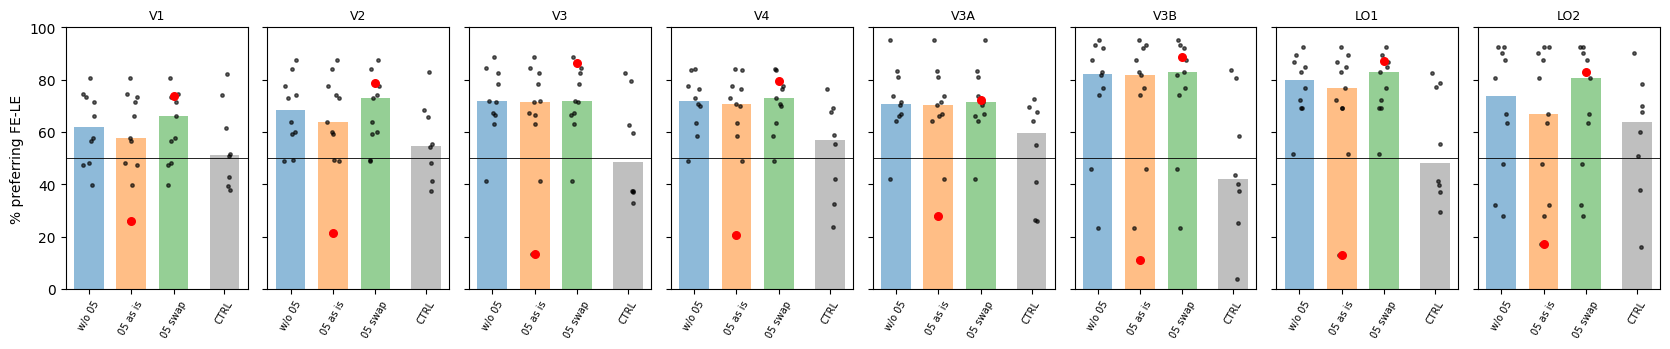

In [5]:
cols = ['amblyopes', 'p_amblyopes_fdr', 'p_ambly_vs_ctrl_fdr']
print(side_by_side(od_tests, cols, 'pref_FE', 50).to_string())
print('\nControls (same in the 3 versions):')
print(od_tests(dfs[versions[0]], 'pref_FE', 50)[['controls', 'p_controls_fdr']].round(3).to_string())
version_plot(od_tests, 'pref_FE', '% preferring FE-LE', 'sub05_versions_od_pref', ref=50)

## 2. OD — weighted median of the vertex OD index (H0 = 0)

    without sub-05                                     sub-05 as labelled                                     sub-05 swapped                                    
         amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr          amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr      amblyopes p_amblyopes_fdr p_ambly_vs_ctrl_fdr
roi                                                                                                                                                             
V1           0.055        0.053 ns            0.315 ns              0.020        0.117 ns            0.545 ns          0.056         0.034 *            0.272 ns
V2           0.095        0.008 **            0.111 ns              0.084         0.043 *            0.275 ns          0.106        0.004 **            0.067 ns
V3           0.151        0.006 **             0.031 *              0.132         0.043 *            0.101 ns          0.170        0.003 **             0.018 *
V4           0.105        0.006 **

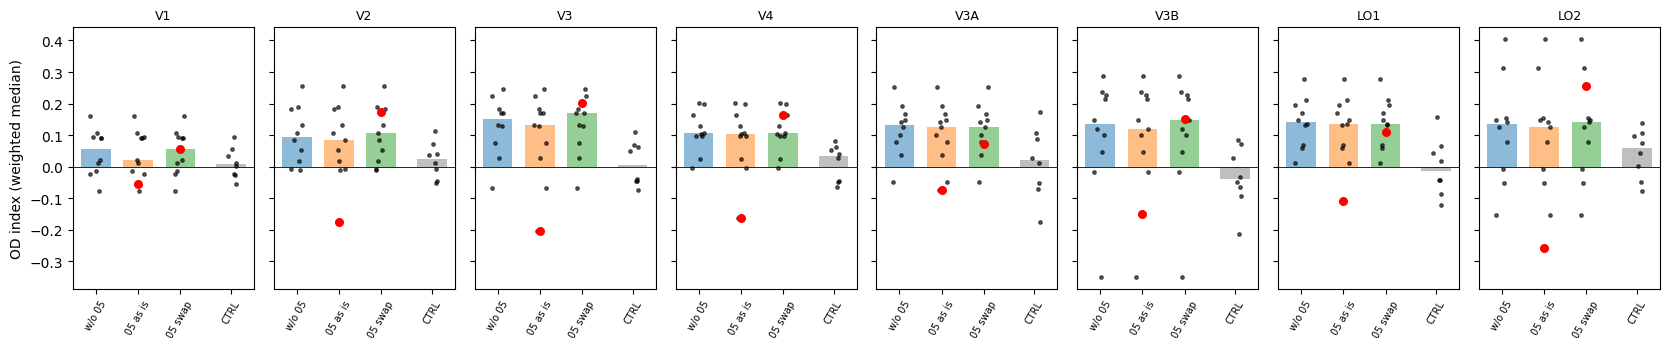

In [6]:
print(side_by_side(od_tests, cols, 'od_index', 0).to_string())
print('\nControls (same in the 3 versions):')
print(od_tests(dfs[versions[0]], 'od_index', 0)[['controls', 'p_controls_fdr']].round(3).to_string())
version_plot(od_tests, 'od_index', 'OD index (weighted median)', 'sub05_versions_od_index', ref=0)

## 3. OD — reproducibility of the OD maps between halves of the runs

Per-run GLM sums (`od_glm_common_cache`), same method as v12: OD map of each half (2 runs), weighted correlation between the halves, median of the 3 splits; split 1 also with crossed labels. Swapping sub-05's eyes changes the sign of both half-maps: its r is unchanged. Only the group statistics can change (with or without sub-05).

In [7]:
splits = {1: ([0, 1], [2, 3]), 2: ([0, 2], [1, 3]), 3: ([0, 3], [1, 2])}


def wpearson(x, y, w):
    return wcorr(x, y, w)


def repro_rows(subject, swap):
    fn = '{}/{}_od-glm-common_runs.npz'.format(glm_cache_dir, subject)
    if not os.path.isfile(fn):
        return []
    z = np.load(fn)
    d = vertex_data[subject]
    dd = swap_eyes(d) if swap else d
    keep_full = (select(dd, 'L') & select(dd, 'R')).values
    w_full = ((dd.prf_rsq_L + dd.prf_rsq_R) / 2).clip(lower=0).values
    pos = pd.Series(np.arange(len(d)), index=d.vertex.values)
    vert = z['vertex']
    ok = np.isin(vert, d.vertex.values)
    idx = pos.reindex(vert[ok]).values
    keep, w_all, roi_names = keep_full[idx], w_full[idx], z['roi'][ok]
    group = 'patient' if subject in patients else 'control'
    fe = 'R' if (group == 'patient' and ambly_eye[subject] == 'L') else 'L'
    fe_i, ae_i = (1, 0) if fe == 'R' else (0, 1)
    if swap:
        fe_i, ae_i = ae_i, fe_i
    sxy, sxx = z['sxy_common'][:, :, ok], z['sxx_common'][:, ok]

    def beta(items):
        with np.errstate(divide='ignore', invalid='ignore'):
            return sum(sxy[e, r] for e, r in items) / sum(sxx[r] for _, r in items)
    out = []
    for split, (ra, rb) in splits.items():
        b = {h: (beta([(fe_i, r1), (fe_i, r2)]), beta([(ae_i, r1), (ae_i, r2)])) for h, (r1, r2) in zip('AB', [ra, rb])}
        bc = {h: (beta([(fe_i, r1), (ae_i, r2)]), beta([(ae_i, r1), (fe_i, r2)])) for h, (r1, r2) in zip('AB', [ra, rb])}
        finite = np.all([np.isfinite(x) for h in 'AB' for x in b[h] + bc[h]], axis=0)
        for roi in rois:
            m = keep & (roi_names == roi) & finite
            w = w_all[m]
            if m.sum() < 10 or w.sum() == 0:
                continue
            mp = lambda bf, ba: (bf[m] - ba[m]) / (np.sum(w * bf[m]) / w.sum() + np.sum(w * ba[m]) / w.sum())
            row = {'subject': subject, 'group': group, 'roi': roi, 'split': split, 'r_true': wpearson(mp(*b['A']), mp(*b['B']), w)}
            if split == 1:
                row['r_crossed'] = wpearson(mp(*bc['A']), mp(*bc['B']), w)
            out.append(row)
    return out

rep_base = pd.DataFrame([r for s in vertex_data for r in repro_rows(s, False)])
rep_swap05 = pd.DataFrame(repro_rows(target, True))
rep = {'without sub-05': rep_base[rep_base.subject != target], 'sub-05 as labelled': rep_base,
       'sub-05 swapped': pd.concat([rep_base[rep_base.subject != target], rep_swap05], ignore_index=True)}
out = {}
for v in versions:
    d = rep[v]
    sh = d.groupby(['subject', 'group', 'roi']).r_true.median().reset_index()
    s1 = d[d.split == 1][['subject', 'roi', 'r_true', 'r_crossed']].rename(columns={'r_true': 'r1'})
    sh = sh.merge(s1, on=['subject', 'roi'])
    rows = []
    for roi in rois:
        g = sh[(sh.roi == roi) & (sh.group == 'patient')]
        rows.append({'roi': roi, 'r (median of 3)': g.r_true.median(), 'p_r>0': wilcoxon_p(g.r_true, alternative='greater'),
                     'r crossed': g.r_crossed.median(), 'p_true>crossed': wilcoxon_p(g.r1, g.r_crossed, alternative='greater')})
    t = pd.DataFrame(rows).set_index('roi')
    for col in ['p_r>0', 'p_true>crossed']:
        q = bh_fdr(t[col]); t[col + ' fdr'] = ['{:.3f} {}'.format(x, stars(x)) for x in q]; t = t.drop(columns=col)
    out[v] = t.round(3)
print('Amblyopes:')
print(pd.concat(out, axis=1).to_string())
print('\nsub-05 r (median of 3 splits), as labelled / swapped:')
print(pd.concat({'as labelled': rep_base[rep_base.subject == target].groupby('roi').r_true.median(),
                 'swapped': rep_swap05.groupby('roi').r_true.median()}, axis=1).reindex(rois).round(3).T.to_string())

Amblyopes:
     without sub-05                                        sub-05 as labelled                                         sub-05 swapped                                       
    r (median of 3) r crossed p_r>0 fdr p_true>crossed fdr    r (median of 3) r crossed p_r>0 fdr p_true>crossed fdr r (median of 3) r crossed p_r>0 fdr p_true>crossed fdr
roi                                                                                                                                                                        
V1            0.439    -0.053  0.004 **            0.022 *              0.483    -0.017  0.002 **            0.011 *           0.483    -0.017  0.002 **            0.011 *
V2            0.644     0.021  0.004 **            0.020 *              0.712     0.004  0.002 **           0.010 **           0.712     0.004  0.002 **           0.010 **
V3            0.607     0.005  0.004 **            0.020 *              0.627     0.000  0.002 **           0.010 **           0.

## 4. pRF — R² of each eye

AE vs FE (paired), AE vs CTRL and FE vs CTRL (Mann-Whitney), FDR over the ROIs.

    without sub-05                                                       sub-05 as labelled                                                       sub-05 swapped                                                      
                AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr                 AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr             AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr
roi                                                                                                                                                                                                                   
V1           0.423  0.454  0.504     0.037 *      0.232 ns      0.965 ns              0.430  0.466  0.504    0.111 ns      0.311 ns      0.840 ns          0.430  0.466  0.504     0.019 *      0.271 ns      0.904 ns
V2           0.287  0.391  0.513    0.004 **      0.195 ns      0.965 ns              0.314  0.390  0.513    0.067 ns      0.217 ns      0.8

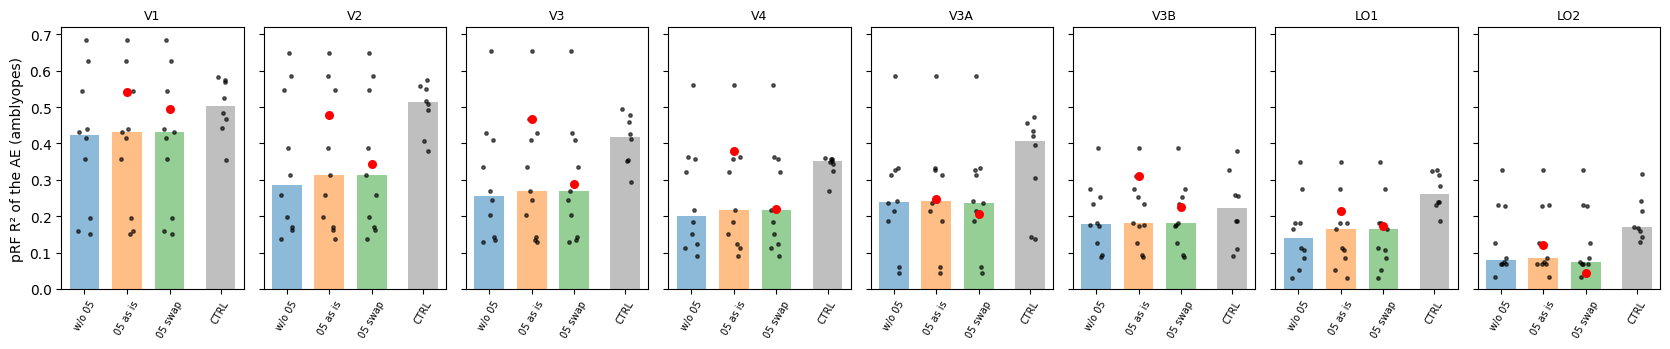

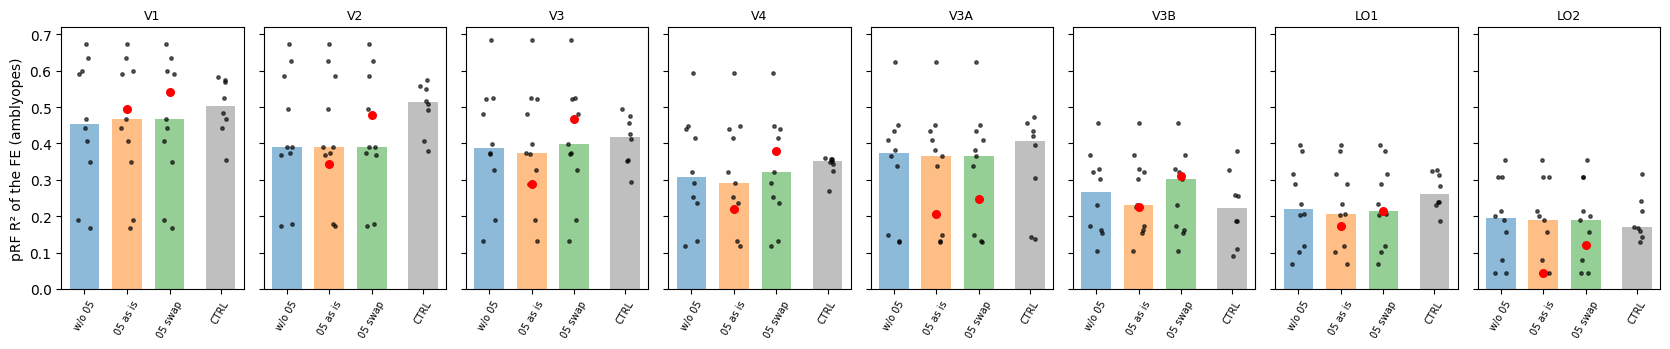

In [8]:
pcols = ['AE', 'FE', 'CTRL', 'p_AE_FE_fdr', 'p_AE_CTRL_fdr', 'p_FE_CTRL_fdr']
print(side_by_side(eye_tests, pcols, 'rsq').to_string())
version_plot(eye_tests, 'rsq_AE', 'pRF R² of the AE (amblyopes)', 'sub05_versions_rsq_AE', ctrl_col='rsq_CTRL')
version_plot(eye_tests, 'rsq_FE', 'pRF R² of the FE (amblyopes)', 'sub05_versions_rsq_FE', ctrl_col='rsq_CTRL')

## 5. pRF — effective size σ/√n at 2°

    without sub-05                                                       sub-05 as labelled                                                       sub-05 swapped                                                      
                AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr                 AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr             AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr
roi                                                                                                                                                                                                                   
V1           1.024  0.746  0.819    0.098 ns      0.237 ns      0.346 ns              0.939  0.762  0.819    0.112 ns      0.310 ns      0.355 ns          0.939  0.745  0.819    0.064 ns      0.310 ns      0.475 ns
V2           1.193  0.930  0.865    0.141 ns      0.055 ns      0.480 ns              1.178  0.954  0.865    0.164 ns      0.066 ns      0.4

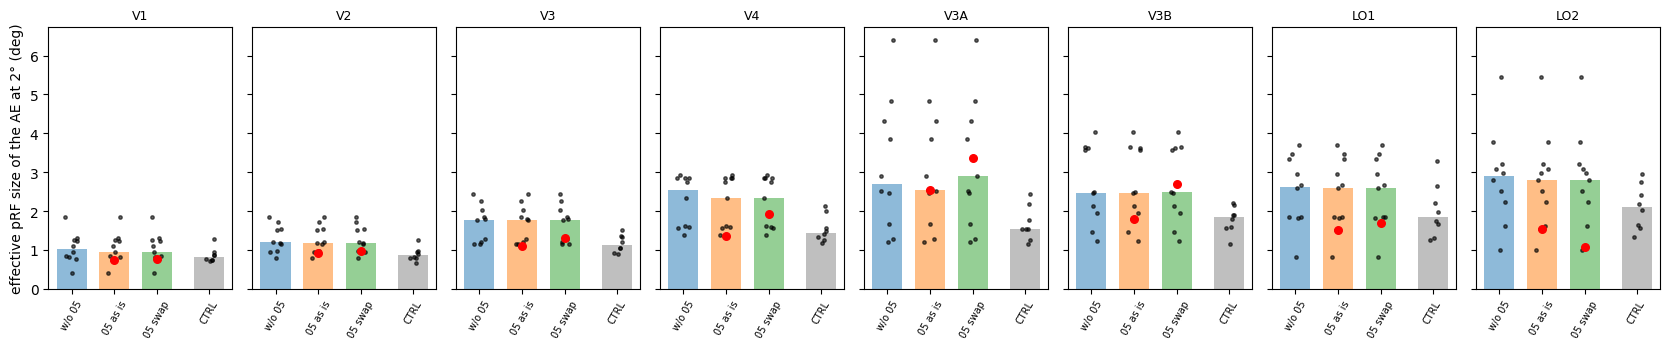

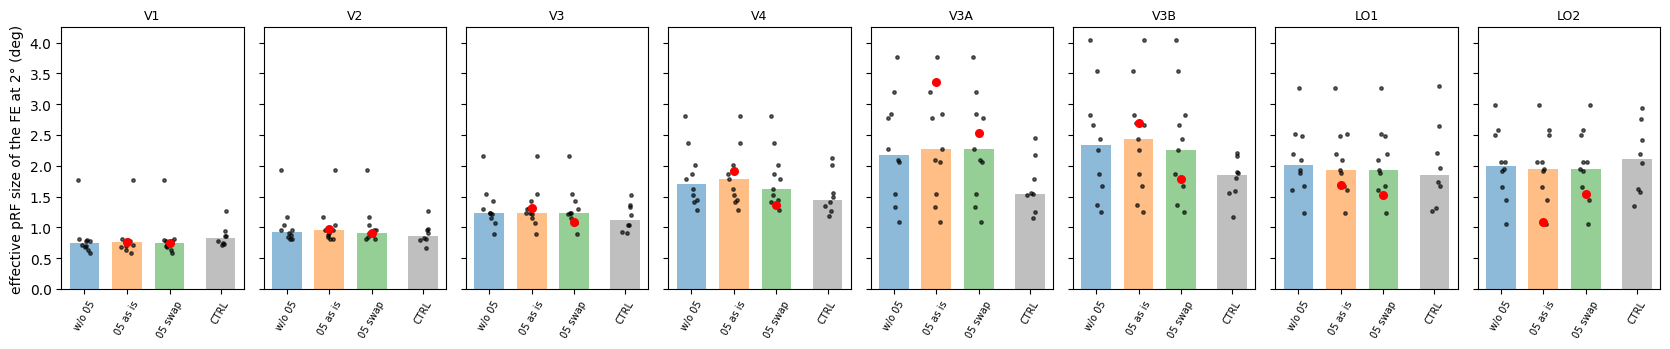

In [9]:
print(side_by_side(eye_tests, pcols, 'size').to_string())
version_plot(eye_tests, 'size_AE', 'effective pRF size of the AE at 2° (deg)', 'sub05_versions_size_AE', ctrl_col='size_CTRL')
version_plot(eye_tests, 'size_FE', 'effective pRF size of the FE at 2° (deg)', 'sub05_versions_size_FE', ctrl_col='size_CTRL')

## 6. pRF — cortical magnification (pCM at 2°)

In [10]:
print(side_by_side(eye_tests, pcols, 'pcm').to_string())

    without sub-05                                                       sub-05 as labelled                                                       sub-05 swapped                                                      
                AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr                 AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr             AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr
roi                                                                                                                                                                                                                   
V1           5.916  6.127  6.317    0.168 ns      0.691 ns      0.686 ns              6.002  6.244  6.317    0.107 ns      0.824 ns      0.686 ns          6.171  6.010  6.317    0.233 ns      0.620 ns      0.726 ns
V2           6.704  7.056  6.014    0.174 ns      0.897 ns      0.686 ns              6.743  7.086  6.014    0.280 ns      0.889 ns      0.6

## 7. pRF — CSS exponent n

In [11]:
print(side_by_side(eye_tests, pcols, 'n').to_string())

    without sub-05                                                       sub-05 as labelled                                                       sub-05 swapped                                                      
                AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr                 AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr             AE     FE   CTRL p_AE_FE_fdr p_AE_CTRL_fdr p_FE_CTRL_fdr
roi                                                                                                                                                                                                                   
V1           0.470  0.425  0.553    0.922 ns      0.654 ns      1.000 ns              0.468  0.414  0.553    0.966 ns      0.717 ns      0.968 ns          0.468  0.414  0.553    0.874 ns      0.717 ns      0.968 ns
V2           0.360  0.367  0.285    0.922 ns      0.654 ns      1.000 ns              0.328  0.360  0.285    0.966 ns      0.717 ns      0.9

## 8. pRF — maps of the two eyes (amblyopes vs controls)

Shift of the pRF centre between the eyes (deg, and relative to the pRF size), correlation of the eccentricity maps of the two eyes. Swapping the eyes does not change these between-eye measures: only the with / without sub-05 versions can differ.

In [12]:
gcols = ['amblyopes', 'controls', 'p_fdr']
for meas, lab in [('shift_deg', 'pRF shift between the eyes (deg)'), ('shift_rel', 'pRF shift (pRF sizes)'),
                  ('ecc_corr', 'eccentricity-map correlation between the eyes')]:
    print('\n' + lab)
    print(side_by_side(group_tests, gcols, meas).to_string())


pRF shift between the eyes (deg)
    without sub-05                    sub-05 as labelled                    sub-05 swapped                   
         amblyopes controls     p_fdr          amblyopes controls     p_fdr      amblyopes controls     p_fdr
roi                                                                                                          
V1           0.930    0.545  0.163 ns              0.922    0.545  0.145 ns          0.922    0.545  0.145 ns
V2           0.946    0.565  0.109 ns              0.894    0.565  0.066 ns          0.894    0.565  0.066 ns
V3           1.324    0.578  0.109 ns              1.313    0.578  0.066 ns          1.313    0.578  0.066 ns
V4           1.200    0.622  0.093 ns              1.217    0.622  0.054 ns          1.217    0.622  0.054 ns
V3A          2.190    1.313  0.274 ns              2.052    1.313  0.238 ns          2.052    1.313  0.238 ns
V3B          1.455    0.846  0.162 ns              1.449    0.846  0.145 ns          1

## 9. Summary: which conclusions depend on sub-05?

For every test: significant (FDR p < 0.05) or not in each version. The rows where the versions disagree are the conclusions that depend on sub-05.

In [13]:
summ = []


def collect(name, fun, pcols_, *args):
    for v in versions:
        s = fun(dfs[v], *args)
        for roi in rois:
            for col in pcols_:
                summ.append({'analysis': name, 'test': col.replace('_fdr', ''), 'roi': roi, 'version': v, 'p_fdr': s.loc[roi, col]})

collect('OD % pref FE', od_tests, ['p_amblyopes_fdr', 'p_ambly_vs_ctrl_fdr'], 'pref_FE', 50)
collect('OD index', od_tests, ['p_amblyopes_fdr', 'p_ambly_vs_ctrl_fdr'], 'od_index', 0)
for meas, name in [('rsq', 'R²'), ('size', 'size at 2°'), ('pcm', 'pCM at 2°'), ('n', 'n')]:
    collect(name, eye_tests, ['p_AE_FE_fdr', 'p_AE_CTRL_fdr', 'p_FE_CTRL_fdr'], meas)
for meas in ['shift_deg', 'shift_rel', 'ecc_corr']:
    collect(meas, group_tests, ['p_fdr'], meas)
summ = pd.DataFrame(summ)
wide = summ.pivot_table(index=['analysis', 'test', 'roi'], columns='version', values='p_fdr').reindex(columns=versions)
sig = wide < 0.05
wide['depends on sub-05'] = sig.nunique(axis=1) > 1
print('Tests significant in at least one version, and whether the versions agree:')
show = wide[(sig.any(axis=1)) | wide['depends on sub-05']]
print(show.round(3).to_string())
print('\n{} tests depend on sub-05 (out of {}):'.format(int(wide['depends on sub-05'].sum()), len(wide)))
print(wide[wide['depends on sub-05']].round(3).to_string())

Tests significant in at least one version, and whether the versions agree:
version                           without sub-05  sub-05 as labelled  sub-05 swapped  depends on sub-05
analysis     test            roi                                                                       
OD % pref FE p_ambly_vs_ctrl LO1           0.069               0.206           0.041               True
                             V3            0.069               0.206           0.041               True
                             V3A           0.069               0.206           0.041               True
                             V3B           0.069               0.206           0.041               True
                             V4            0.069               0.206           0.041               True
             p_amblyopes     LO1           0.004               0.045           0.002              False
                             LO2           0.042               0.087           0.021         